In [1]:
!wget "https://raw.githubusercontent.com/Rnoozy/Gold-Prices-Prediction/main/gld_price_data.csv"


--2026-08-25 03:15:50--  https://raw.githubusercontent.com/Rnoozy/Gold-Prices-Prediction/main/gld_price_data.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 130560 (128K) [text/plain]
Saving to: ‘gld_price_data.csv’

gld_price_data.csv  100%[===================>] 127.50K  --.-KB/s    in 0.004s  

2026-08-25 03:15:51 (31.4 MB/s) - ‘gld_price_data.csv’ saved [130560/130560]



In [38]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [39]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score



In [40]:
df = pd.read_csv("gld_price_data.csv")
df.head()

,Date,SPX,GLD,USO,SLV,EUR/USD
0,1/2/2008,1447.160034,84.860001,78.470001,15.180,1.471692
1,1/3/2008,1447.160034,85.570000,78.370003,15.285,1.474491
2,1/4/2008,1411.630005,85.129997,77.309998,15.167,1.475492
3,1/7/2008,1416.180054,84.769997,75.500000,15.053,1.468299
4,1/8/2008,1390.189941,86.779999,76.059998,15.590,1.557099


In [41]:
df.isna().sum()

,0
Date,0
SPX,0
GLD,0
USO,0
SLV,0
EUR/USD,0


In [42]:
df.shape

(2290, 6)

In [43]:
df.describe()

,SPX,GLD,USO,SLV,EUR/USD
count,2290.000000,2290.000000,2290.000000,2290.000000,2290.000000
mean,1654.315776,122.732875,31.842221,20.084997,1.283653
std,519.111540,23.283346,19.523517,7.092566,0.131547
min,676.530029,70.000000,7.960000,8.850000,1.039047
25%,1239.874969,109.725000,14.380000,15.570000,1.171313
50%,1551.434998,120.580002,33.869999,17.268500,1.303297
75%,2073.010070,132.840004,37.827501,22.882500,1.369971
max,2872.870117,184.589996,117.480003,47.259998,1.598798


In [44]:
print("Preprocessing data...")
if 'Date' in df.columns:
    df = df.drop(columns=['Date'])

X = df.drop(columns=['GLD'])
y = df['GLD']

Preprocessing data...


In [45]:
X_train ,X_test , y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [46]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

In [47]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [48]:
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train.values, dtype=torch.float32)
y_test = torch.tensor(y_test.values, dtype=torch.float32)

In [49]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

torch.Size([1832, 4])
torch.Size([458, 4])
torch.Size([1832])
torch.Size([458])


In [28]:
class Model(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer = nn.Sequential(
        nn.Linear(X_train.shape[1],100),
        nn.ReLU(),
        nn.Linear(100,50),
        nn.ReLU(),
        nn.Linear(50,1)
    )

  def forward(self,x):
    return self.layer(x)
model = Model()


In [29]:
loss_fn = nn.MSELoss()

In [30]:
optimizer = torch.optim.Adam(model.parameters(),lr=0.001)

In [31]:
# Calculate accuracy (a classification metric)
def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item() # torch.eq() calculates where two tensors are equal
    acc = (correct / len(y_pred)) * 100
    return acc

In [56]:
torch.manual_seed(42)

# Set the number of epochs
epochs = 1000

for epoch in range(epochs):

    # --- 1. TRAINING PHASE ---
    model.train()

    # Forward pass
    y_pred = model(X_train)

    # Calculate loss (Squeeze y_pred to match y_train shape!)
    loss = loss_fn(y_pred.squeeze(), y_train)

    # Optimizer zero grad
    optimizer.zero_grad()

    # Backpropagation
    loss.backward()

    # Optimizer step
    optimizer.step()

    # --- 2. TESTING PHASE ---
    model.eval()
    with torch.inference_mode():
        # Forward pass on test data
        test_pred = model(X_test)

        # Calculate test loss (Squeeze test_pred here too!)
        test_loss = loss_fn(test_pred.squeeze(), y_test)

    # Optional: Print out what is happening every 10 epochs
    if epoch % 10 == 0:
        print(f"Epoch: {epoch} | Train Loss: {loss.item():.4f} | Test Loss: {test_loss.item():.4f}")

Epoch: 0 | Train Loss: 133.8058 | Test Loss: 157.6492
Epoch: 10 | Train Loss: 129.7016 | Test Loss: 153.0013
Epoch: 20 | Train Loss: 125.8114 | Test Loss: 148.5834
Epoch: 30 | Train Loss: 122.0907 | Test Loss: 144.3580
Epoch: 40 | Train Loss: 118.5183 | Test Loss: 140.3016
Epoch: 50 | Train Loss: 115.0949 | Test Loss: 136.4063
Epoch: 60 | Train Loss: 111.8107 | Test Loss: 132.6552
Epoch: 70 | Train Loss: 108.6592 | Test Loss: 129.0362
Epoch: 80 | Train Loss: 105.6323 | Test Loss: 125.5540
Epoch: 90 | Train Loss: 102.7194 | Test Loss: 122.2091
Epoch: 100 | Train Loss: 99.9135 | Test Loss: 118.9963
Epoch: 110 | Train Loss: 97.2103 | Test Loss: 115.9032
Epoch: 120 | Train Loss: 94.6074 | Test Loss: 112.9348
Epoch: 130 | Train Loss: 92.1012 | Test Loss: 110.0696
Epoch: 140 | Train Loss: 89.6936 | Test Loss: 107.3080
Epoch: 150 | Train Loss: 87.3777 | Test Loss: 104.6453
Epoch: 160 | Train Loss: 85.1542 | Test Loss: 102.0784
Epoch: 170 | Train Loss: 83.0274 | Test Loss: 99.6124
Epoch: 180 |

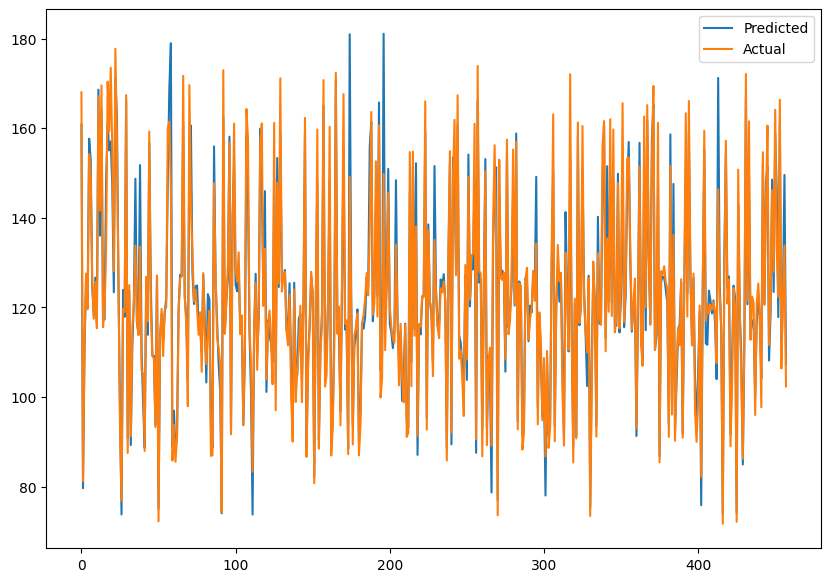

In [57]:
plt.figure(figsize=(10, 7))
# Plot training & validation loss values
plt.plot(test_pred.detach().numpy(), label='Predicted')
plt.plot(y_test.detach().numpy(), label='Actual')
plt.legend(loc='upper right')
plt.show()


In [58]:
# Convert tensors back to numpy arrays for sklearn
y_test_np = y_test.detach().numpy()
test_pred_np = test_pred.detach().numpy()

# Calculate R-squared
r2 = r2_score(y_test_np, test_pred_np)
print(f"R-Squared Score: {r2:.4f}")

R-Squared Score: 0.9313


In [59]:
# Save the model's weights
torch.save(model.state_dict(), 'gold_price_model.pth')
print("Model saved successfully!")

Model saved successfully!
